# Lab 4-01：用 LLM 把文字拆成三元組

**目標**：把 21 段海賊王劇情摘要，交給本地小模型抽成 (主體, 關係, 客體) 三元組，
量出它抽得多準，再用正規化與人工校對把錯修掉，存成 `data/triples.json` 給後面三本用。

**你會學到**
- 不給規格，模型每次發明不同的關係名稱
- 用 Pydantic 定義「只能用這 8 種關係」，再交給模型做受限輸出
- 用標準答案量 precision／recall，知道錯在哪
- 實體正規化：同一個人的不同叫法要合併，否則圖會裂成孤島

**前置**：模組 3 的 embedding 概念；Ollama 已有 `qwen2.5:3b` 與 `bge-m3`。全部跑完約 5～8 分鐘。

**對應投影片**：「實體、關係、屬性」「LLM 抽取三元組」「Lab 4 圖譜長相」「踩坑：別名、成本、語法」

![LLM 抽取三元組的流程](images/extract_triples.jpg)

*圖：由左往右讀。段落交給 LLM，Pydantic 規格限制它能輸出的格式；抽出的三元組先經過驗證與正規化（別名表在這裡合併稱呼），錯的丟掉，對的才存進 triples.json。*

## Step 1：讀語料

語料是課程自己寫的摘要（`data/one_piece_summaries.md`）。為了模擬真實文件，
同一個人在不同段落會用不同稱呼：「魯夫」「蒙其·D·魯夫」「草帽小子」都是同一個人。

In [1]:
import json
import re
import time
from pathlib import Path

text = Path("data/one_piece_summaries.md").read_text(encoding="utf-8")

paragraphs = []
for block in re.split(r"^## ", text, flags=re.M)[1:]:
    head, _, body = block.partition("\n")
    pid, title = head.split(maxsplit=1)
    paragraphs.append({"id": pid, "title": title, "text": body.strip()})

print("段落數：", len(paragraphs))
for p in paragraphs[:3]:
    print(f"[{p['id']}] {p['title']}：{p['text']}")

段落數： 21
[01] 風車村的少年：魯夫出身東海的風車村。他小時候誤吃了橡膠果實，身體從此能像橡皮一樣伸長，代價是再也不會游泳。
[02] 紅髮與草帽：香克斯是紅髮海賊團的船長，曾帶著船員在風車村住了一段時間。為了從海獸口中救下村裡的男孩，他失去了左手臂。離開前，他把自己的草帽交給男孩保管，約好等男孩成為了不起的海賊再還給他。
[03] 出海：十七歲那年，蒙其·D·魯夫戴著那頂草帽，獨自划小船出海，成立了草帽海賊團並擔任船長。他的夢想是成為海賊王。


## Step 2：先不給規格，看它怎麼抽

最直覺的做法：叫模型「列出三元組」。挑三段試試，注意關係欄位寫了什麼。

In [2]:
from course_utils.llm import chat

NAIVE = "從下面的文字抽出知識圖譜的三元組，每行一個，格式：(主體, 關係, 客體)。"

for p in paragraphs[2:5]:
    print(f"--- 段落 {p['id']}")
    print(chat([{"role": "user", "content": NAIVE + "\n\n" + p["text"]}]))

--- 段落 03
(蒙其·D·魯夫, 成立, 草帽海賊團)
(蒙其·D·魯夫, 擔任, 船長)
(蒙其·D·魯夫, 梦想, 成為海賊王)
--- 段落 04
(羅羅亞·索隆, 是, 草帽海賊團的劍士)
(羅羅亞·索隆, 加入, 第一個加入的同伴)
(羅羅亞·索隆, 使用, 三把刀的三刀流)
(羅羅亞·索隆, 梦想, 成為世界第一大劍豪)
--- 段落 05
(古伊娜, 是, 霜月村道場的女兒)
(古伊娜, 对于, 那个剑士少年, 是对手)
(古伊娜, 拥有, 一把名刀)
(古伊娜, 拥有, 道一文字)
(古伊娜, 患病/去世, 没有具体原因)
(古伊娜, 之后, 刀, 被交到少年手上)
(少年, 对于, 古伊娜, 有誓言)


能讀，但沒法用：同一種關係，這段寫「是船長」，那段寫「擔任」「為…的船長」；
客體有時是名字，有時是一整句話。圖資料庫裡每一種寫法都會變成不同的邊，查詢時根本對不起來。

解法跟模組 2 的結構化輸出一樣：**先定規格，再叫模型照規格填**。
把「開放式生成」變成「從固定類別裡挑」，錯得比較少。

## Step 3：用 Pydantic 定規格

我們只允許 8 種關係。每種關係的主體與客體類型是固定的（投影片「Lab 4 圖譜長相」的擴充版）：

```
(:Person)-[:CAPTAIN_OF | MEMBER_OF]->(:Crew)
(:Person)-[:OWNS]->(:Treasure)
(:Person)-[:DREAMS_OF]->(:Dream)
(:Person)-[:FROM]->(:Place)
(:Person)-[:HAS_FATHER | BROTHER_OF | DEFEATED]->(:Person)
```

In [3]:
from typing import Literal

from pydantic import BaseModel, ValidationError

Relation = Literal[
    "CAPTAIN_OF", "MEMBER_OF", "OWNS", "DREAMS_OF",
    "FROM", "HAS_FATHER", "BROTHER_OF", "DEFEATED",
]


class Triple(BaseModel):
    subject: str
    relation: Relation
    object: str


class Extraction(BaseModel):
    triples: list[Triple]


schema = Extraction.model_json_schema()
print(json.dumps(schema["$defs"]["Triple"]["properties"]["relation"], ensure_ascii=False))

{"enum": ["CAPTAIN_OF", "MEMBER_OF", "OWNS", "DREAMS_OF", "FROM", "HAS_FATHER", "BROTHER_OF", "DEFEATED"], "title": "Relation", "type": "string"}


`relation` 只能是那 8 個字串之一。這份 JSON Schema 會直接交給 Ollama 當「受限輸出」的格式：
模型在生成時就只能吐出符合 schema 的 JSON，不只是事後檢查。

再寫一份 prompt，把每種關係的線索、規則與一個範例講清楚。範例刻意用虛構人物，免得模型直接抄答案。

In [4]:
SYSTEM = """你是知識圖譜抽取器。從一段文字抽出 (主體, 關係, 客體) 三元組。只准用這 8 種關係：

| 關係 | 主體 | 客體 | 文字裡的線索 |
|---|---|---|---|
| CAPTAIN_OF | 人物 | 海賊團 | 「…的船長」「帶頭」 |
| MEMBER_OF | 人物 | 海賊團 | 「是…的劍士／航海士／成員」 |
| OWNS | 人物 | 物品 | 「吃了…果實」「擁有」「保管」 |
| DREAMS_OF | 人物 | 目標 | 「夢想是…」 |
| FROM | 人物 | 地方 | 「出身…」 |
| HAS_FATHER | 人物 | 人物 | 「X 的父親是 Y」→ (X, HAS_FATHER, Y) |
| BROTHER_OF | 人物 | 人物 | 「哥哥」「結拜兄弟」 |
| DEFEATED | 人物 | 人物 | 「打倒」「打敗」 |

規則：
1. 主體、客體都要是文字裡出現的名字，寫最短的叫法（「魯夫」，不要「十七歲的魯夫」）。
2. 「他」「她」要換成前面提到的名字；換不出來就整條不要。
3. 文字沒有線索的關係就不要輸出，寧可少不要錯；不准寫「某人」「未知」。
4. 只輸出 JSON。

範例文字：小明是藍鯨海賊團的船長，出身南島。他吃了泡泡果實，夢想是環遊世界。他的妹妹小華是藍鯨海賊團的廚師。
範例輸出：{"triples": [{"subject": "小明", "relation": "CAPTAIN_OF", "object": "藍鯨海賊團"}, {"subject": "小明", "relation": "FROM", "object": "南島"}, {"subject": "小明", "relation": "OWNS", "object": "泡泡果實"}, {"subject": "小明", "relation": "DREAMS_OF", "object": "環遊世界"}, {"subject": "小華", "relation": "MEMBER_OF", "object": "藍鯨海賊團"}]}"""

RESPONSE_FORMAT = {"type": "json_schema", "json_schema": {"name": "extraction", "schema": schema}}

## Step 4：抽一段看看

In [5]:
def extract(paragraph: str) -> list[dict]:
    """抽一段；小模型偶爾會卡在重複輸出而被 Ollama 中止，就稍微提高溫度重試一次。"""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "文字：" + paragraph}]
    for temperature in (0.0, 0.3):
        try:
            raw = chat(messages, temperature=temperature, response_format=RESPONSE_FORMAT, max_tokens=600)
            return [t.model_dump() for t in Extraction.model_validate_json(raw).triples]
        except (RuntimeError, ValidationError) as exc:
            print(f"  （重試：{type(exc).__name__}）")
    return []


sample = paragraphs[9]
print(sample["text"])
for t in extract(sample["text"]):
    print(t)

騙人布出身西羅布村，是草帽海賊團的狙擊手，彈弓打得極準。他常說大話，但夢想是成為勇敢的海上戰士。他的父親耶穌布很早就離開村子上了海賊船。
{'subject': '騙人布', 'relation': 'MEMBER_OF', 'object': '草帽海賊團'}
{'subject': '騙人布', 'relation': 'DREAMS_OF', 'object': '成為勇敢的海上戰士'}
{'subject': '騙人布', 'relation': 'CAPTAIN_OF', 'object': '未知'}
{'subject': '耶穌布', 'relation': 'HAS_FATHER', 'object': '騙人布'}


## Step 5：全部抽一遍

21 段、每段一次呼叫。正式專案會平行送出；這裡依序跑，方便看進度。

In [6]:
start = time.time()
raw_triples = []
for p in paragraphs:
    found = extract(p["text"])
    raw_triples += [{**t, "paragraph": p["id"]} for t in found]
    print(f"[{p['id']}] {len(found)} 條")
print(f"共 {len(raw_triples)} 條，花了 {time.time() - start:.0f} 秒")

[01] 2 條
  （重試：ValidationError）
[02] 10 條
[03] 1 條
[04] 3 條
[05] 5 條
[06] 3 條
[07] 3 條
[08] 4 條
[09] 1 條
[10] 4 條
[11] 2 條
[12] 3 條
[13] 4 條
[14] 4 條
[15] 4 條
[16] 5 條
[17] 5 條
[18] 3 條
[19] 3 條
[20] 1 條
[21] 3 條
共 73 條，花了 89 秒


In [7]:
for t in raw_triples:
    print(t["paragraph"], t["subject"], t["relation"], t["object"])

01 魯夫 FROM 東海
01 魯夫 OWNS 橡膠果實
02 香克斯 CAPTAIN_OF 紅髮海賊團
02 香克斯 MEMBER_OF 紅髮海賊團
02 香克斯 HAS_FATHER 未知
02 香克斯 OWNS 草帽
02 香克斯 DEFEATED 海獸
02 香克斯 HAS_FATHER 未知
02 香克斯 HAS_FATHER 未知
02 香克斯 HAS_FATHER 未知
02 男孩 MEMBER_OF 紅髮海賊團
02 男孩 HAS_FATHER 香克斯
03 蒙其·D·魯夫 CAPTAIN_OF 草帽海賊團
04 羅羅亞·索隆 CAPTAIN_OF 草帽海賊團
04 羅羅亞·索隆 MEMBER_OF 草帽海賆團
04 羅羅亞·索隆 DREAMS_OF 成為世界第一大劍豪
05 古伊娜 MEMBER_OF 霜月村道場
05 少年 BROTHER_OF 古伊娜
05 少年 HAS_FATHER 古伊娜
05 少年 OWNS 道一文字
05 少年 DREAMS_OF 最強的目標
06 索隆 MEMBER_OF 霜月村
06 索隆 OWNS 白鞘刀
06 索隆 DREAMS_OF 環遊世界
07 娜美 MEMBER_OF 草帽海賊團
07 娜美 FROM 可可亞西村
07 娜美 DREAMS_OF 親手畫出全世界的地圖
08 阿龍 CAPTAIN_OF 阿龍海賊團
08 阿龍 MEMBER_OF 魚人
08 阿龍 DEFEATED 可可亞西村
08 阿龍 HAS_FATHER 未知
09 草帽小子 DEFEATED 阿龍
10 騙人布 MEMBER_OF 草帽海賊團
10 騙人布 DREAMS_OF 成為勇敢的海上戰士
10 騙人布 CAPTAIN_OF 未知
10 耶穌布 HAS_FATHER 騙人布
11 耶穌布 MEMBER_OF 紅髮海賊團
11 耶穌布 HAS_FATHER 故鄉的兒子
12 哲夫 MEMBER_OF 海上餐廳巴拉蒂
12 香吉士 MEMBER_OF 海上餐廳巴拉蒂
12 香吉士 CAPTAIN_OF 紅腳
13 香吉士 MEMBER_OF 草帽海賊團
13 香吉士 DREAMS_OF All Blue
13 香吉士 HAS_FATHER 未知
13 香吉士 DEFEATED 未知
14 喬巴 OWNS 人人果實
14 喬巴 FR

先自己掃一遍，你大概會看到這幾種錯（每次跑不完全一樣）：

- **方向反了**：父子、師徒這種關係，主體客體很容易對調。
- **關係標錯**：船員被標成 `CAPTAIN_OF`，或把綽號塞進 `DREAMS_OF`。
- **客體不是實體**：「左手臂」「可可亞西村村民」這種片語也被當成節點。
- **同一個人多個名字**：「蒙其·D·魯夫」「草帽小子」「魯夫」各自成了一個節點。

用眼睛看只能抽查。要知道到底準不準，得跟標準答案比。

## Step 6：跟標準答案比，量 precision／recall

`data/gold_triples.json` 是人工逐段標的 47 條三元組。比對規則放寬一點：
主體與關係要一樣，客體只要互相包含就算對（「成為海賊王」對「海賊王」）。

- **precision**：模型抽出來的，有幾成是對的
- **recall**：該抽的，模型抽到了幾成

In [8]:
gold = json.loads(Path("data/gold_triples.json").read_text(encoding="utf-8"))


def same(a: dict, b: dict) -> bool:
    return (a["subject"] == b["subject"] and a["relation"] == b["relation"]
            and (a["object"] in b["object"] or b["object"] in a["object"]))


def score(pred: list[dict]) -> tuple[float, float]:
    precision = sum(any(same(p, g) for g in gold) for p in pred) / max(len(pred), 1)
    recall = sum(any(same(p, g) for p in pred) for g in gold) / len(gold)
    return precision, recall


p0, r0 = score(raw_triples)
print(f"原始輸出：precision {p0:.0%}，recall {r0:.0%}")

原始輸出：precision 37%，recall 57%


兩個數字都不高。但先別急著換大模型：有一部分「錯」其實是**名字沒對齊**，
例如模型抽出 (蒙其·D·魯夫, CAPTAIN_OF, 草帽海賊團)，內容對，只是主體叫法跟標準答案不同。這是正規化要解決的事。

## Step 7：找出疑似別名

投影片「踩坑」的修法是：**向量找候選 → 字串規則過濾 → 人（或 LLM）裁決 → 合併**。
先把所有出現過的名字列出來，用兩條便宜的規則找候選：

1. 一個名字包含另一個（「火拳艾斯」包含「艾斯」）
2. bge-m3 向量很像

In [9]:
import numpy as np

from course_utils.llm import embed

names = sorted({t["subject"] for t in raw_triples} | {t["object"] for t in raw_triples})
print(len(names), "個不同的名字")

vecs = np.array(embed(names))
vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)
sim = vecs @ vecs.T

candidates = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        contains = a in b or b in a
        if contains or sim[i, j] > 0.80:
            candidates.append((sim[i, j], a, b, "包含" if contains else "向量"))

for s, a, b, why in sorted(candidates, reverse=True)[:25]:
    print(f"{s:.2f}  {a} ↔ {b}  （{why}）")

66 個不同的名字
0.84  阿龍 ↔ 阿龍海賊團  （包含）
0.83  霜月村 ↔ 霜月村道場  （包含）
0.81  少年 ↔ 男孩  （向量）
0.81  草帽 ↔ 草帽小子  （包含）
0.81  草帽大船團 ↔ 草帽海賆團  （向量）
0.76  草帽 ↔ 草帽海賊團  （包含）
0.73  草帽 ↔ 草帽大船團  （包含）
0.72  火拳艾斯 ↔ 艾斯  （包含）
0.71  草帽 ↔ 草帽海賆團  （包含）
0.70  索隆 ↔ 羅羅亞·索隆  （包含）
0.62  蒙其·D·魯夫 ↔ 魯夫  （包含）


候選裡有真的別名，也有假警報（「草帽」和「草帽海賊團」互相包含，卻是完全不同的東西）。
而「草帽小子 = 魯夫」這種綽號，字串和向量都抓不到：它要靠讀過故事的人才知道。

所以最後一步還是**人來拍板**，寫成一張別名表。真實專案裡這張表會隨資料一直長大。

In [10]:
ALIASES = {
    "魯夫": ["蒙其·D·魯夫", "草帽小子"],
    "索隆": ["羅羅亞·索隆", "海賊獵人"],
    "娜美": ["小賊貓"],
    "香吉士": ["黑足"],
    "艾斯": ["火拳艾斯", "火拳"],
    "白鬍子": ["愛德華·紐蓋特"],
    "風車村": ["東海的風車村"],
    "和道一文字": ["道一文字", "白鞘刀"],
}
CANONICAL = {alias: name for name, aliases in ALIASES.items() for alias in aliases}
DREAM_PREFIXES = ("成為", "親手")


def normalize(t: dict) -> dict:
    subject = CANONICAL.get(t["subject"], t["subject"])
    obj = CANONICAL.get(t["object"], t["object"])
    if t["relation"] == "DREAMS_OF":
        for prefix in DREAM_PREFIXES:
            obj = obj.removeprefix(prefix)
    return {**t, "subject": subject, "object": obj}


normalized = [normalize(t) for t in raw_triples]
names_after = {t["subject"] for t in normalized} | {t["object"] for t in normalized}
print(f"節點數：{len(names)} → {len(names_after)}")

p1, r1 = score(normalized)
print(f"正規化後：precision {p1:.0%}，recall {r1:.0%}")

節點數：66 → 61
正規化後：precision 48%，recall 74%


## Step 8：用類型擋掉不合理的邊

每種關係的客體類型是固定的，所以可以反推每個名字「應該」是什麼類型。
同一個名字被推成兩種類型，就代表某條邊一定錯了，例如「霜月村」既是地方（FROM）又是海賊團（MEMBER_OF）。

In [11]:
from collections import defaultdict

RANGE = {
    "CAPTAIN_OF": "Crew", "MEMBER_OF": "Crew", "OWNS": "Treasure", "DREAMS_OF": "Dream",
    "FROM": "Place", "HAS_FATHER": "Person", "BROTHER_OF": "Person", "DEFEATED": "Person",
}

types = defaultdict(set)
for t in normalized:
    types[t["subject"]].add("Person")
    types[t["object"]].add(RANGE[t["relation"]])

conflicts = {n: ts for n, ts in types.items() if len(ts) > 1}
for n, ts in conflicts.items():
    print(n, sorted(ts))

未知 ['Crew', 'Person']
可可亞西村 ['Person', 'Place']
魚人 ['Crew', 'Place']


這些衝突是給人看的警示燈，不是自動判決：衝突兩邊哪條才對，要回原文看。
下一步人工校對時，這份清單就是優先檢查的地方。

## Step 9：把每一步的效果畫出來

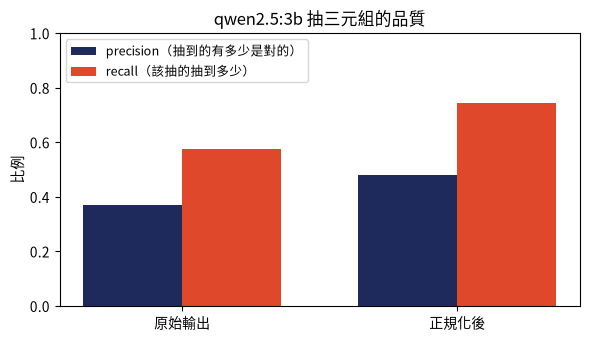

In [12]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

stages = ["原始輸出", "正規化後"]
fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(len(stages))
ax.bar(x - 0.18, [p0, p1], width=0.36, label="precision（抽到的有多少是對的）", color="#1f2a5c")
ax.bar(x + 0.18, [r0, r1], width=0.36, label="recall（該抽的抽到多少）", color="#e0482c")
ax.set_xticks(x, stages)
ax.set_ylim(0, 1)
ax.set_ylabel("比例")
ax.set_title("qwen2.5:3b 抽三元組的品質")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

正規化只動名字，不會讓錯的關係變對，所以 precision 的提升有上限。
剩下的錯（方向反、關係標錯、客體不是實體）要靠更好的模型、更細的 prompt，或人工校對。

## Step 10：人工校對，存檔

後面三本 notebook 要比較「圖檢索 vs 向量檢索」，圖本身不能有錯，否則比的是抽取品質而不是檢索方式。
所以最後一步模擬人工校對：

- 模型抽對的，保留並標 `source: "llm"`
- 模型漏掉的，由人補上並標 `source: "manual"`
- 模型抽錯的，丟掉（印出來看看丟了什麼）

課堂上我們用 `gold_triples.json` 代替人工審查；真實專案裡，這一步是抽樣檢查加上 Step 8 的衝突清單。

In [13]:
final, rejected = [], []
for g in gold:
    hit = any(same(t, g) for t in normalized)
    final.append({**g, "source": "llm" if hit else "manual"})
rejected = [t for t in normalized if not any(same(t, g) for g in gold)]

n_llm = sum(t["source"] == "llm" for t in final)
print(f"最終 {len(final)} 條：LLM 抽到 {n_llm} 條，人工補上 {len(final) - n_llm} 條")
print(f"丟掉 {len(rejected)} 條錯誤，例如：")
for t in rejected[:8]:
    print("  ", t["subject"], t["relation"], t["object"])

最終 47 條：LLM 抽到 35 條，人工補上 12 條
丟掉 38 條錯誤，例如：
   魯夫 FROM 東海
   香克斯 MEMBER_OF 紅髮海賊團
   香克斯 HAS_FATHER 未知
   香克斯 DEFEATED 海獸
   香克斯 HAS_FATHER 未知
   香克斯 HAS_FATHER 未知
   香克斯 HAS_FATHER 未知
   男孩 MEMBER_OF 紅髮海賊團


最後把節點也整理出來：每個節點有名字、類型（之後當 Neo4j 的標籤）和別名。
別名在下一本做「問題裡提到了誰」的比對時會用到。

In [14]:
node_types = {}
for t in final:
    node_types.setdefault(t["subject"], "Person")
    node_types.setdefault(t["object"], RANGE[t["relation"]])

nodes = [{"name": n, "label": lbl, "aliases": ALIASES.get(n, [])} for n, lbl in sorted(node_types.items())]
out = {"nodes": nodes, "triples": final}
Path("data/triples.json").write_text(json.dumps(out, ensure_ascii=False, indent=1), encoding="utf-8")

from collections import Counter

print(Counter(n["label"] for n in nodes))
print(Counter(t["relation"] for t in out["triples"]))

Counter({'Person': 17, 'Treasure': 9, 'Dream': 8, 'Place': 6, 'Crew': 6})
Counter({'MEMBER_OF': 12, 'OWNS': 11, 'DREAMS_OF': 8, 'FROM': 7, 'CAPTAIN_OF': 6, 'DEFEATED': 1, 'HAS_FATHER': 1, 'BROTHER_OF': 1})


## 試試看

1. 把 `SYSTEM` 裡的範例刪掉，只留關係表，重跑 Step 5～6。precision 和 recall 各變了多少？
2. 在 Step 7 加上「LLM 裁決」：把一對候選名字和兩段原文丟給模型，問它「是不是同一個人」，只回答是或否。它能認出「草帽小子 = 魯夫」嗎？
3. 把 `max_tokens` 改成 100，看看長段落會發生什麼事。為什麼受限輸出還是可能失敗？

## 小結

- 抽三元組要先定規格：固定的關係清單＋每種關係的主客體類型，用 Pydantic 寫成 schema 交給模型。
- 小模型抽得出大概，但方向、關係、別名都會錯；用標準答案量 precision／recall，比用眼睛抽查可靠。
- 正規化合併別名、類型衝突標出可疑的邊，最後由人拍板。下一本用 networkx 把 `triples.json` 建成圖，手寫多跳查詢。